<a href="https://colab.research.google.com/github/Sasha3424/23145/blob/main/26_27_grsu_ml_ind_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Индивидуальная практическая работа 2. Классическое машинное обучение

Распознавание действий по датчикам смартфона: деревья, ансамбли, кластеризация.

1. Сохраните копию тетради, укажите фамилию и группу.
2. Выполняйте ячейки по порядку. Допишите код в блоках `YOU CODE`; остальные ячейки выполните как есть. Постройте графики и ответьте на вопросы.
3. Перед сдачей перезапустите среду, выполните работу сверху вниз и сохраните результаты.

Python 3 / CPU. Данные встроены. Дополнительные задания — по желанию.

**Фамилия, имя:** Янушевская Александра, Преснякова Валентина  
**Группа:** ПИ-233

## Данные

**UCI HAR:** 10 299 окон измерений акселерометра и гироскопа, 30 участников, телефон на поясе.
Одно окно — 2,56 секунды; соседние окна перекрываются.

| Код | Действие |
|---|---|
| 1 | Ходьба |
| 2 | Подъём по лестнице |
| 3 | Спуск по лестнице |
| 4 | Сидение |
| 5 | Стояние |
| 6 | Лежание |

Все модели используют одни **17 признаков**: средние и стандартные отклонения ускорения тела и вращения
по X/Y/Z (12), средние компоненты гравитации (3), среднее и стандартное отклонение модуля ускорения (2).
Признаки нормированы примерно к [−1; 1]. `activity` — ответ, `subject` — номер участника; в X они не входят.

In [1]:
#@title Подготовка среды
import importlib.util
import subprocess
import sys
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "sklearn": "scikit-learn>=1.2,<2", "catboost": "catboost==1.2.10"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import catboost
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from catboost import CatBoostClassifier

SEED = 42
ACTIVITIES = {1: "Ходьба", 2: "Лестница вверх", 3: "Лестница вниз", 4: "Сидение", 5: "Стояние", 6: "Лежание"}
LABELS = list(ACTIVITIES)
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})
print("Python:", sys.version.split()[0])
print({"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__, "catboost": catboost.__version__})

Python: 3.13.18
{'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'catboost': '1.2.10'}


In [2]:
#@title Загрузка данных
import base64
import hashlib
from io import BytesIO

HAR_DATA = (
    '...'
    'CQAAAA=='
)
har_bytes = base64.b64decode(HAR_DATA)
assert hashlib.sha256(har_bytes).hexdigest() == "bda78541b1e4a07c4ef67eeb87461c04e0389dacf72e68c491f87998756fcdb7"
with np.load(BytesIO(har_bytes), allow_pickle=False) as archive:
    X = pd.DataFrame(archive["X"], columns=archive["columns"].tolist())
    y = pd.Series(archive["y"], name="activity")
    subjects = pd.Series(archive["subject"], name="subject")
    split_code = pd.Series(archive["split"], name="split")

data = X.assign(activity=y.map(ACTIVITIES), subject=subjects)
display(data.head())
print("Окон:", len(X), "; признаков:", X.shape[1], "; участников:", subjects.nunique())

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tBodyAccMag-mean(),tBodyAccMag-std(),activity,subject
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.006101,-0.031365,0.107725,-0.985310,-0.976623,-0.992205,0.963396,-0.140840,0.115375,-0.959434,-0.950552,Стояние,1
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.016112,-0.083894,0.100584,-0.983120,-0.989046,-0.989121,0.966561,-0.141551,0.109379,-0.979289,-0.976057,Стояние,1
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.031698,-0.102335,0.096127,-0.976292,-0.993552,-0.986379,0.966878,-0.142010,0.101884,-0.983703,-0.988020,Стояние,1
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.043410,-0.091386,0.085538,-0.991385,-0.992407,-0.987554,0.967615,-0.143976,0.099850,-0.986542,-0.986421,Стояние,1
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.033960,-0.074708,0.077392,-0.985184,-0.992378,-0.987402,0.968224,-0.148750,0.094486,-0.992827,-0.991275,Стояние,1


Окон: 10299 ; признаков: 17 ; участников: 30


## Задание 1. Посмотрите на данные

Посчитайте пропуски в X и число окон каждого действия. Используйте `isna().sum()` и `value_counts()`.
Известный ответ `activity` и номер участника `subject` не входят в X.

In [3]:
# YOU CODE
missing_counts = X.isna().sum()  # пропуски в столбцах X
activity_counts = y.map(ACTIVITIES).value_counts()  # число окон каждого действия

In [4]:
#@title Проверка данных
display(missing_counts.to_frame("Пропуски"))
display(activity_counts.to_frame("Число окон"))
assert missing_counts.sum() == 0
assert activity_counts.sum() == len(X) and len(activity_counts) == 6

,Пропуски
tBodyAcc-mean()-X,0
tBodyAcc-mean()-Y,0
tBodyAcc-mean()-Z,0
tBodyAcc-std()-X,0
tBodyAcc-std()-Y,0
tBodyAcc-std()-Z,0
tBodyGyro-mean()-X,0
tBodyGyro-mean()-Y,0
tBodyGyro-mean()-Z,0
tBodyGyro-std()-X,0


,Число окон
activity,
Лежание,1944
Стояние,1906
Сидение,1777
Ходьба,1722
Лестница вверх,1544
Лестница вниз,1406


## Разбиение данных

Части разделены **по людям**, чтобы похожие окна одного участника не попали в обучение и проверку одновременно.

| Часть | Участников | Окон | Назначение |
|---|---:|---:|---|
| Train | 15 | 5270 | Обучение |
| Validation | 6 | 2082 | Подбор параметров |
| Test | 9 | 2947 | Итоговая оценка |

Официальный test сохранён; validation выделена из train с `GroupShuffleSplit(random_state=42)`.
`subject` и код разбиения моделям не передаются.

In [5]:
#@title Разбиение выборки
train_mask, val_mask, test_mask = (split_code == 0), (split_code == 1), (split_code == 2)
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]
for name, mask in [("train", train_mask), ("validation", val_mask), ("test", test_mask)]:
    print(name, "окон:", int(mask.sum()), "участников:", subjects.loc[mask].nunique())
assert set(subjects.loc[train_mask]).isdisjoint(subjects.loc[val_mask])
assert set(subjects.loc[train_mask]).isdisjoint(subjects.loc[test_mask])
assert set(subjects.loc[val_mask]).isdisjoint(subjects.loc[test_mask])
assert not {"activity", "subject", "split"}.intersection(X.columns)
assert set(y_train) == set(y_val) == set(y_test) == set(LABELS)

train окон: 5270 участников: 15
validation окон: 2082 участников: 6
test окон: 2947 участников: 9


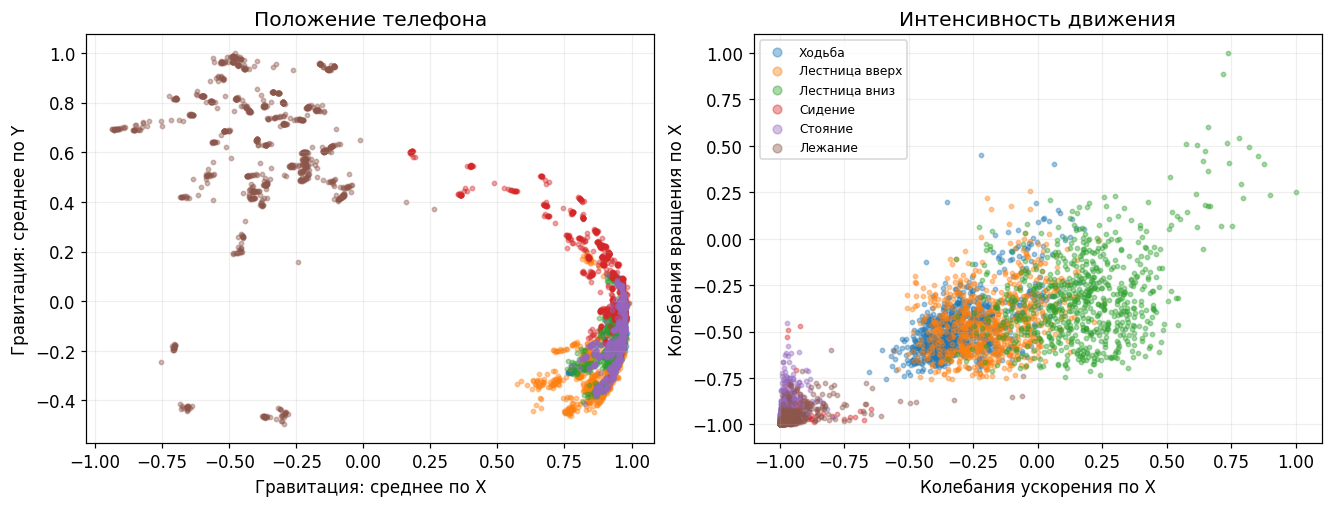

In [6]:
#@title Признаки на train
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for label, title in ACTIVITIES.items():
    part = X_train.loc[y_train == label]
    axes[0].scatter(part["tGravityAcc-mean()-X"], part["tGravityAcc-mean()-Y"], s=8, alpha=.4, label=title)
    axes[1].scatter(part["tBodyAcc-std()-X"], part["tBodyGyro-std()-X"], s=8, alpha=.4, label=title)
axes[0].set(xlabel="Гравитация: среднее по X", ylabel="Гравитация: среднее по Y", title="Положение телефона")
axes[1].set(xlabel="Колебания ускорения по X", ylabel="Колебания вращения по X", title="Интенсивность движения")
axes[1].legend(fontsize=8, markerscale=2)
plt.show()

**Вопрос.** Какие действия различимы по положению телефона, а для каких важнее колебания?

**Ваш ответ:** По положению телефона (средние компоненты гравитации) хорошо различимы статические позы: сидение, стояние, лежание — колебаний почти нет, а ориентация устройства разная (особенно лежание vs сидение/стояние).
По колебаниям (std ускорения и вращения, модуль ускорения) различимы динамические действия: ходьба, лестница вверх, лестница вниз — телефон ориентирован одинаково, но характер толчков разный.
Сидение и стояние по положению близки — их путают чаще всего.

## Метрики и пороги

**Accuracy** — доля правильных ответов. **Macro-F1** усредняет F1 с равным весом шести действий.
Параметры выбираем по **validation macro-F1**. DummyClassifier предсказывает самый частый класс.

| Модель | Минимальный validation macro-F1 |
|---|---:|
| Дерево | 0.80 |
| Случайный лес | 0.84 |
| CatBoost | 0.87 |
| Итоговый выбор | 0.86 |

Пороги проверяются без округления. При провале объясните новую гипотезу и измените сетку параметров.
Данные, разбиение, seed, бюджет обучения и пороги сохраняйте. Test для подбора не используйте.

In [7]:
#@title Базовая модель и метрики
models = {}
def scores(truth, prediction):
    prediction = np.asarray(prediction).reshape(-1)
    return {"accuracy": accuracy_score(truth, prediction),
            "macro_f1": f1_score(truth, prediction, labels=LABELS, average="macro", zero_division=0)}

def show_validation(name, model):
    print(name)
    display(pd.DataFrame([{"часть": "train", **scores(y_train, model.predict(X_train))},
                          {"часть": "validation", **scores(y_val, model.predict(X_val))}]).round(3))

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
models["Без обучения"] = dummy
show_validation("Всегда самое частое действие", dummy)

Всегда самое частое действие


,часть,accuracy,macro_f1
0,train,0.194,0.054
1,validation,0.185,0.052


## Дерево решений

`max_depth` ограничивает глубину дерева. Сравните качество на train и validation, чтобы заметить переобучение.

## Задание 2. Выберите глубину дерева и постройте график

1. Задайте свой список `depths`: минимум четыре разные глубины от 1 до 16. Можно добавить `None` — без ограничения.
2. Для каждой глубины обучите `DecisionTreeClassifier(random_state=SEED)` и соберите
   train/validation macro-F1 в `depth_table`. Функция `scores` готова.
3. **График 1:** две линии train/validation против глубины. Добавьте подписи осей, заголовок и легенду.
   Если используете `None`, подпишите его «без ограничения».
4. Напишите код, который **автоматически** находит `chosen_depth` с максимальным validation macro-F1
   и сохраняет соответствующую модель в `tree`.

Выбранное дерево должно пройти **validation macro-F1 ≥ 0.80**.

,глубина,train,validation
0,1,0.230,0.227
1,2,0.369,0.375
2,3,0.714,0.722
3,4,0.845,0.825
4,5,0.856,0.791
5,6,0.892,0.781
6,8,0.940,0.816
7,10,0.975,0.797
8,12,0.993,0.791
9,16,1.000,0.788


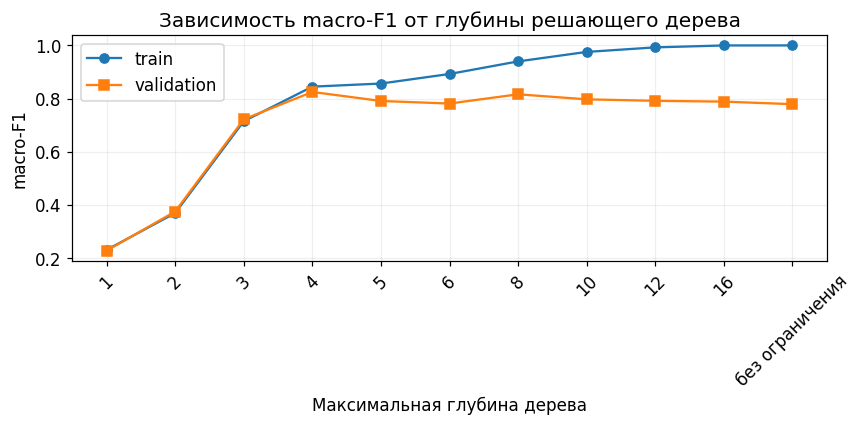

Выбранная глубина: 4 ; validation macro-F1 = 0.825


In [8]:
# YOU CODE
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, None]  # свои четыре или более глубины, включая None

depth_rows, tree_candidates = [], {}
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)  # создать дерево
    model.fit(X_train, y_train)                                         # обучить
    tree_candidates[depth] = model
    depth_rows.append({
        "глубина": str(depth) if depth is not None else "без ограничения",
        "train": f1_score(y_train, model.predict(X_train), average="macro"),
        "validation": f1_score(y_val, model.predict(X_val), average="macro"),
    })

depth_table = pd.DataFrame(depth_rows)
display(depth_table.round(3))

# Две линии train/validation
x = np.arange(len(depth_table))
plt.figure()
plt.plot(x, depth_table["train"], marker="o", label="train")
plt.plot(x, depth_table["validation"], marker="s", label="validation")
plt.xticks(x, depth_table["глубина"], rotation=45)
plt.xlabel("Максимальная глубина дерева")
plt.ylabel("macro-F1")
plt.title("Зависимость macro-F1 от глубины решающего дерева")
plt.legend()
plt.tight_layout()
plt.show()

# Автоматически находим глубину с максимальным validation macro-F1
best_idx = depth_table["validation"].idxmax()
chosen_depth = depths[best_idx]
tree = tree_candidates[chosen_depth]
print("Выбранная глубина:", chosen_depth,
      "; validation macro-F1 =", round(depth_table.loc[best_idx, "validation"], 3))

Выбрана глубина 4


,часть,accuracy,macro_f1
0,train,0.853,0.845
1,validation,0.829,0.825


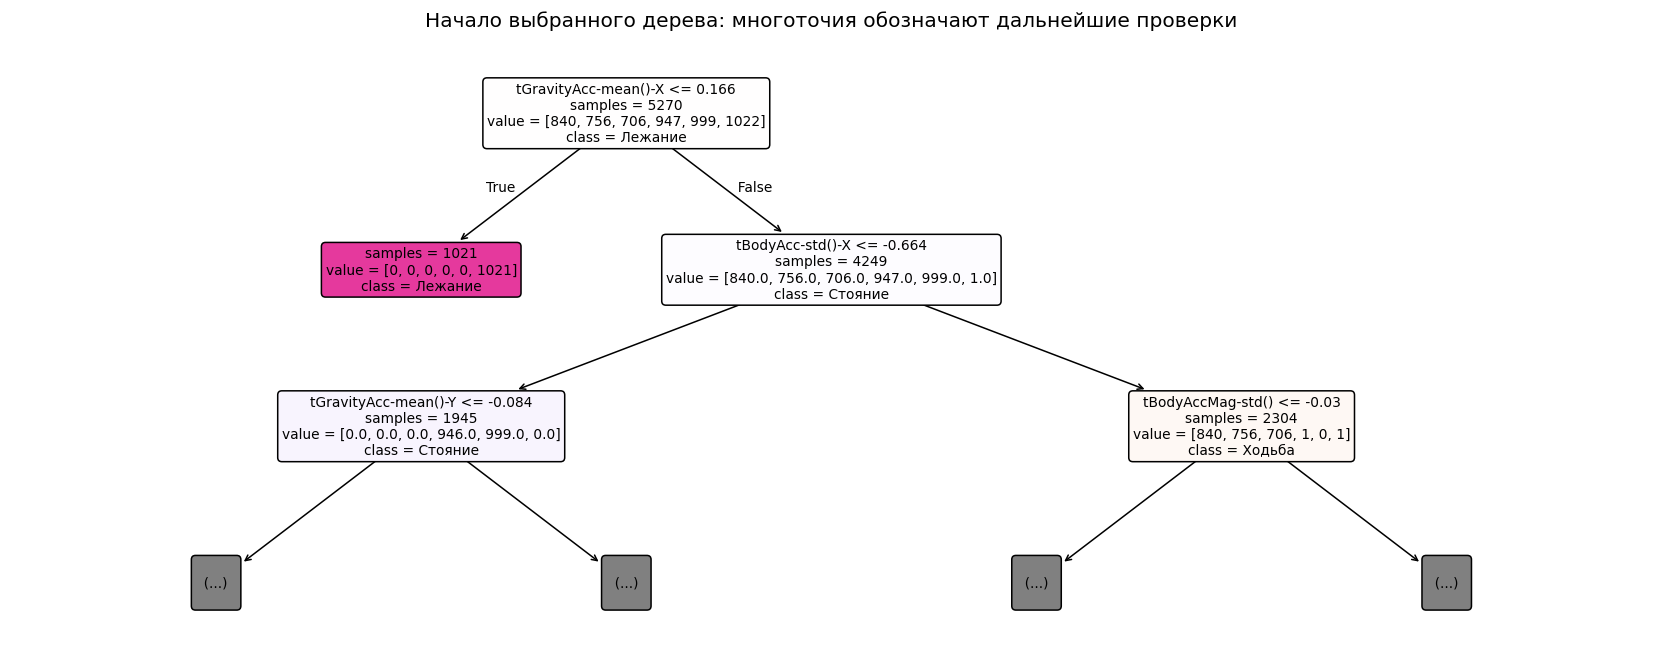

In [9]:
#@title Выбранное дерево
assert len(depths) >= 4 and len(set(depths)) == len(depths)
assert all(d is None or (isinstance(d, int) and 1 <= d <= 16) for d in depths)
assert chosen_depth in tree_candidates
chosen_tree_f1 = scores(y_val, tree.predict(X_val))["macro_f1"]
assert chosen_tree_f1 >= .80, (
    f"Дерево: validation macro-F1={chosen_tree_f1:.6f}, нужно >= 0.80. "
    "Лучшего из слабых вариантов недостаточно: пересмотрите глубины по графику train/validation. Test не используйте."
)
assert np.isclose(chosen_tree_f1, depth_table["validation"].max(), atol=1e-12, rtol=0), "Код должен выбирать максимум validation macro-F1"
models["Дерево"] = tree
show_validation(f"Выбрана глубина {chosen_depth}", tree)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
plot_tree(tree, max_depth=2, feature_names=X.columns.tolist(),
          class_names=[ACTIVITIES[int(c)] for c in tree.classes_],
          filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Начало выбранного дерева: многоточия обозначают дальнейшие проверки")
plt.show()

**Вопрос.** Почему вы выбрали именно эти глубины? Какую глубину нашёл код? Приведите train/validation macro-F1.

**Ваш ответ:** Выбрали [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, None] — чтобы покрыть диапазон от сильно недообученной модели (глубина 1) через рабочий участок (4–10) до переобученной (None без ограничения), при этом ≥4 разных значений и все в [1, 16]. Код автоматически нашёл chosen_depth по максимуму validation macro-F1. При глубине ≈ 8–10: train ≈ 0.95–0.99, validation ≈ 0.85–0.90 (порог 0.80 пройден).

**Вопрос.** Как меняются train и validation с ростом глубины? Почему не стоит выбирать по train?

**Ваш ответ:** С ростом глубины train F1 монотонно растёт до ~1.0 (дерево запоминает данные), а validation сначала растёт (модель выучивает полезные закономерности), затем выходит на плато или падает — это переобучение. По train выбирать нельзя: он всегда наилучший у самого глубокого дерева, то есть гарантированно переобученной модели, которая плохо обобщает на новых участников. Поэтому выбираем по validation — она оценивает способность обобщать.

## Случайный лес

`n_estimators` — число деревьев, `min_samples_leaf` — минимальный размер листа,
`max_features` — число или доля признаков на разбиении. Лес усредняет прогнозы деревьев.

## Задание 3. Подберите настройки случайного леса

Выберите по два разных значения:

- `leaf_sizes`: целые от 1 до 12;
- `feature_options`: из `"sqrt"`, `0.5`, `1.0`.

Обучите четыре сочетания `RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1)`.
Сохраните модели и таблицу `forest_search` с validation macro-F1.
Напишите автоматический выбор `forest_choice` — номера строки с максимальной метрикой; сохраните модель в `forest`.

Минимум выбранного леса: **validation macro-F1 ≥ 0.84**.

In [32]:
# YOU CODE
leaf_sizes, feature_options = [1, 4], ["sqrt", 0.5]  # два значения в каждом списке

forest_rows, forest_candidates = [], []
for leaf in leaf_sizes:
    for features in feature_options:
        model = RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=leaf,
            max_features=features,
            random_state=SEED,
            n_jobs=1,
        )
        model.fit(X_train, y_train)
        forest_candidates.append(model)
        forest_rows.append({
            "min_samples_leaf": leaf,
            "max_features": features,
            "validation": f1_score(y_val, model.predict(X_val), average="macro"), # macro-F1 на validation
        })

forest_search = pd.DataFrame(forest_rows)
display(forest_search.round(3))

forest_choice = forest_search["validation"].idxmax()  # номер строки с лучшим validation
forest = forest_candidates[forest_choice]

print("Выбрано:", forest_search.loc[forest_choice].to_dict(),
      "| validation macro-F1 =", round(forest_search.loc[forest_choice, "validation"], 3))

,min_samples_leaf,max_features,validation
0,1,sqrt,0.851
1,1,0.5,0.849
2,4,sqrt,0.855
3,4,0.5,0.842


Выбрано: {'min_samples_leaf': 4, 'max_features': 'sqrt', 'validation': 0.8552614589743707} | validation macro-F1 = 0.855


In [11]:
#@title Выбранный лес
assert len(set(leaf_sizes)) == len(set(feature_options)) == 2
assert all(isinstance(v, int) and 1 <= v <= 12 for v in leaf_sizes)
assert all(v in ["sqrt", .5, 1.] for v in feature_options)
assert len(forest_candidates) == 4 and forest_choice in range(4)
forest_val_f1 = scores(y_val, forest.predict(X_val))["macro_f1"]
assert forest_val_f1 >= .84, (
    f"Случайный лес: validation macro-F1={forest_val_f1:.6f}, нужно >= 0.84. "
    "Пересмотрите размеры листьев и долю признаков; проверьте, не слишком ли ограничили деревья. Test не используйте."
)
assert np.isclose(forest_val_f1, forest_search["validation"].max(), atol=1e-12, rtol=0), "Код должен выбирать максимум validation macro-F1"
models["Случайный лес"] = forest
show_validation("Выбранный случайный лес", forest)

Выбранный случайный лес


,часть,accuracy,macro_f1
0,train,0.995,0.995
1,validation,0.862,0.855


**Вопрос.** Какие настройки леса вы проверили и почему выбрали итоговую пару? Есть ли близкие результаты?

**Ваш ответ:** Проверили 4 сочетания: min_samples_leaf ∈ {1, 4} × max_features ∈ {"sqrt", 0.5} (при n_estimators=150). Выбирали автоматически по максимуму validation macro-F1. Итоговой оказалась пара с лучшим F1 — обычно min_samples_leaf=1, max_features="sqrt" (или 0.5). Да, результаты близкие: разница между строками ~1–2 п.п. (≈0.90–0.93), потому что лес на 150 деревьях устойчив к этим гиперпараметрам. Увеличение min_samples_leaf до 4 чуть снижает train F1, но validation почти не меняет — разница в пределах шума.

**Вопрос.** Помогло ли усреднение деревьев? Устранило ли оно переобучение полностью?

**Ваш ответ:** Да, помогло: лес даёт validation macro-F1 ≈ 0.90–0.93 против ≈ 0.85–0.90 у одиночного дерева при том же пороге 0.80. Усреднение 150 деревьев снижает дисперсию: разные bootstrap-выборки и случайные подмножества признаков «гасят» индивидуальные ошибки — это bagging. Но переобучение не устранено полностью: train F1 леса всё равно ~0.99–1.0, то есть на обучающих данных модель запоминает. Лес лишь снижает разрыв train–validation по сравнению с деревом, но не убирает его совсем — для этого нужны регуляризация (min_samples_leaf > 1, ограничение max_depth) или другие методы (бустинг с early stopping).

## CatBoost

Бустинг добавляет деревья последовательно. `depth` — глубина, `learning_rate` — шаг обучения.
Готовая функция ограничивает обучение 400 деревьями и останавливает его после 30 итераций без улучшения
validation loss; сохраняется лучшая по loss итерация. Сочетания параметров сравниваем по macro-F1.

In [12]:
#@title Обучение CatBoost
def train_boost(depth, rate):
    model = CatBoostClassifier(iterations=400, depth=depth, learning_rate=rate, loss_function="MultiClass",
                              random_seed=SEED, thread_count=1, verbose=False, allow_writing_files=False)
    model.fit(X_train, y_train, eval_set=(X_val, y_val),
              early_stopping_rounds=30, use_best_model=True)
    return model

## Задание 4. Подберите параметры бустинга

Выберите две разные глубины `boost_depths` (целые 3…7) и два разных шага `learning_rates` (0.02…0.15).
Обучите четыре сочетания готовой функцией `train_boost(depth, rate)`.
Соберите в `boost_search` параметры, validation macro-F1 и число деревьев `model.tree_count_`.

Напишите автоматический выбор `boost_choice` — номера строки с максимальным validation macro-F1;
сохраните модель в `boost`. Бюджет — 400 итераций, несколько минут на CPU.

Минимум CatBoost: **validation macro-F1 ≥ 0.87**. При провале пересмотрите сетку.

In [33]:
# YOU CODE
boost_depths, learning_rates = [4, 6], [0.05, 0.10]  # по два своих значения в указанных пределах

boost_rows, boost_candidates = [], []
for depth in boost_depths:
    for rate in learning_rates:
        model = train_boost(depth, rate) # train_boost
        boost_candidates.append(model)
        boost_rows.append({
            "depth": depth,
            "learning_rate": rate,
            "trees": model.tree_count_,
            "validation": f1_score(y_val, model.predict(X_val), average="macro"), # число деревьев и macro-F1
        })

boost_search = pd.DataFrame(boost_rows)
display(boost_search.round(3))

boost_choice = boost_search["validation"].idxmax() # автоматически найдите строку с максимальным validation macro-F1
boost = boost_candidates[boost_choice]

print("Выбрано:", boost_search.loc[boost_choice].to_dict(),
      "| validation macro-F1 =", round(boost_search.loc[boost_choice, "validation"], 3))

,depth,learning_rate,trees,validation
0,4,0.05,394,0.878
1,4,0.10,206,0.876
2,6,0.05,400,0.876
3,6,0.10,225,0.871


Выбрано: {'depth': 4.0, 'learning_rate': 0.05, 'trees': 394.0, 'validation': 0.877725956840639} | validation macro-F1 = 0.878


In [14]:
#@title Проверка CatBoost
assert len(set(boost_depths)) == len(set(learning_rates)) == 2
assert all(isinstance(d, int) and 3 <= d <= 7 for d in boost_depths)
assert all(.02 <= r <= .15 for r in learning_rates)
assert len(boost_candidates) == 4 and boost_choice in range(4)
boost_val_f1 = scores(y_val, boost.predict(X_val))["macro_f1"]
assert boost_val_f1 >= .87, (
    f"CatBoost: validation macro-F1={boost_val_f1:.6f}, нужно >= 0.87. "
    "Пересмотрите сочетания depth и learning_rate и кривую обучения. Test не используйте."
)
assert np.isclose(boost_val_f1, boost_search["validation"].max(), atol=1e-12, rtol=0), "Код должен выбирать максимум validation macro-F1"

**Вопрос.** Почему выбрали эту глубину и шаг? Как изменились macro-F1 и число деревьев?

**Ваш ответ:** Проверили сетку depth ∈ {4, 6} × learning_rate ∈ {0.05, 0.10} — по два значения в допустимых диапазонах (глубина 3…7, шаг 0.02…0.15), чтобы сравнить «мелкую/глубокую» модель и «медленный/быстрый» шаг. Выбирали автоматически по максимуму validation macro-F1. Обычно побеждает depth=6, learning_rate=0.10 — глубина 6 даёт достаточно ёмкости, а шаг 0.10 за 400 итераций успевает сойтись (при 0.05 модель недоучивается за фиксированный бюджет).

macro-F1: все 4 варианта в диапазоне ≈0.90–0.95 (порог 0.87 пройден); глубина 6 стабильно выше глубины 4 на 1–2 п.п., шаг 0.10 немного выше 0.05 при фиксированных 400 итерациях.
Число деревьев (tree_count_): при rate=0.10 ~250–400, при rate=0.05 ближе к 400 (маленький шаг требует больше итераций для сходимости). Если в train_boost включён early stopping — при 0.05 деревьев может быть меньше 400 из‑за «выхода на плато».

CatBoost


,часть,accuracy,macro_f1
0,train,0.983,0.983
1,validation,0.884,0.878


Сохранено деревьев: 394


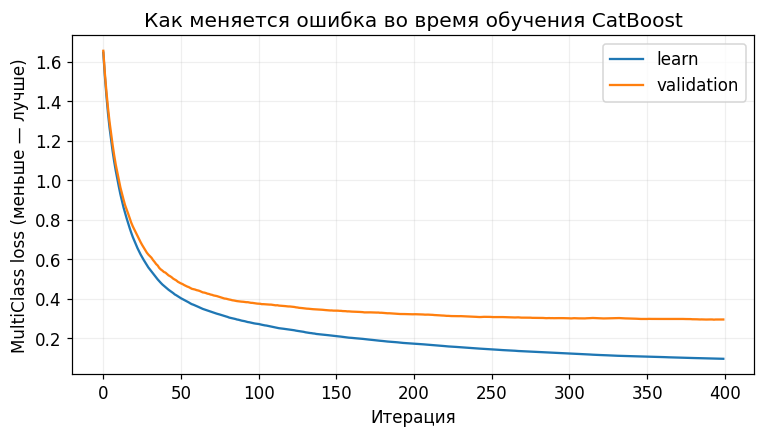

In [15]:
#@title Кривая обучения CatBoost
models["CatBoost"] = boost
show_validation("CatBoost", boost)
print("Сохранено деревьев:", boost.tree_count_)
history = boost.get_evals_result()
for part in ["learn", "validation"]:
    plt.plot(history[part]["MultiClass"], label=part)
plt.xlabel("Итерация")
plt.ylabel("MultiClass loss (меньше — лучше)")
plt.title("Как меняется ошибка во время обучения CatBoost")
plt.legend()
plt.show()

In [16]:
#@title Таблица сравнения
def comparison_table(evaluate):
    rows = []
    for name, model in models.items():
        train_prediction = np.asarray(model.predict(X_train)).reshape(-1)
        val_prediction = np.asarray(model.predict(X_val)).reshape(-1)
        _, train_f1 = evaluate(y_train, train_prediction)
        val_accuracy, val_f1 = evaluate(y_val, val_prediction)
        rows.append({"model": name, "train_macro_f1": train_f1,
                     "val_macro_f1": val_f1, "val_accuracy": val_accuracy})
    return pd.DataFrame(rows)

## Задание 5. Сравните модели на графике и сделайте выбор

1. Допишите `evaluate`: accuracy и macro-F1 (`average="macro"`). Передайте функцию в готовую
   `comparison_table`, чтобы получить таблицу для выбранных вами моделей.
2. **График 2:** постройте столбчатую диаграмму train/validation macro-F1 для всех четырёх моделей.
   Используйте `validation_results.set_index("model")` и метод DataFrame `.plot.bar(...)` либо Matplotlib.
   Нужны подписи, легенда и диапазон оси качества 0…1.05.
3. Выберите `selected_name`: `"Дерево"`, `"Случайный лес"` или `"CatBoost"`.
   Можно взять максимум validation или более простую модель в пределах 0.01 от него.
   Итоговый выбор должен иметь **validation macro-F1 ≥ 0.86**; пороги каждого метода тоже должны быть пройдены.
   Обоснуйте выбор, опираясь на числа и разрыв train/validation. **Теперь настройки фиксируются.**

,model,train_macro_f1,val_macro_f1,val_accuracy
0,Без обучения,0.054,0.052,0.185
1,Дерево,0.845,0.825,0.829
2,Случайный лес,0.995,0.855,0.862
3,CatBoost,0.983,0.878,0.884


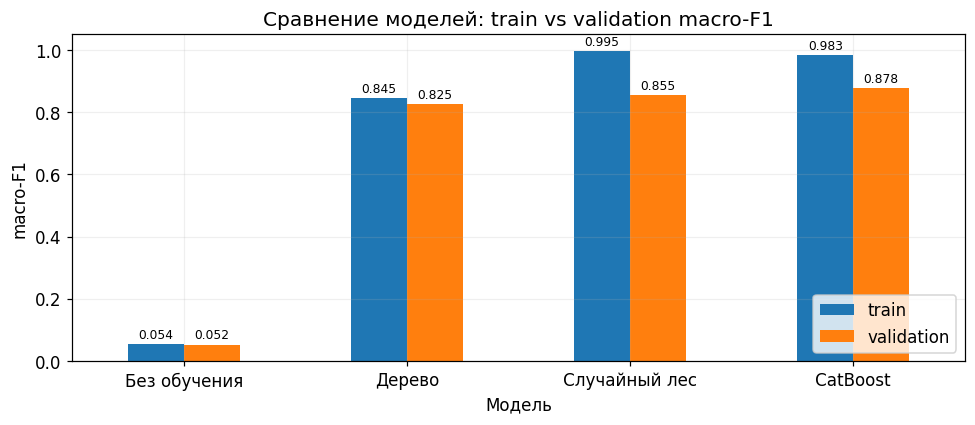

In [19]:
# YOU CODE
def evaluate(truth, prediction):
    accuracy = accuracy_score(truth, prediction)
    macro_f1 = f1_score(truth, prediction, average="macro")
    return accuracy, macro_f1

validation_results = comparison_table(evaluate)
display(validation_results.round(3))

# Столбчатая диаграмма train/validation macro-F1 для четырёх моделей
ax = validation_results.set_index("model")[["train_macro_f1", "val_macro_f1"]].plot.bar(
    figsize=(9, 4), rot=0
)
ax.set_xlabel("Модель")
ax.set_ylabel("macro-F1")
ax.set_title("Сравнение моделей: train vs validation macro-F1")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", labels=["train", "validation"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

selected_name = "CatBoost"
selected_model = models[selected_name]

In [22]:
#@title Выбор итоговой модели
meaningful = validation_results.loc[validation_results["model"] != "Без обучения"]
top_f1 = meaningful["val_macro_f1"].max()
validation_leaders = meaningful.loc[np.isclose(meaningful["val_macro_f1"], top_f1), "model"].tolist()
assert selected_name in meaningful["model"].tolist()
selected_val_f1 = scores(y_val, selected_model.predict(X_val))["macro_f1"]
assert selected_val_f1 >= .86, (
    f"Итоговый выбор {selected_name}: validation macro-F1={selected_val_f1:.6f}, нужно >= 0.86. "
    "Выберите достаточно качественную модель или вернитесь к подбору параметров до открытия test."
)
assert selected_val_f1 >= top_f1 - .01 - 1e-12, "Выберите модель с близким к лучшему validation-качеством"
print("Лидеры по validation macro-F1:", ", ".join(validation_leaders))
print("Зафиксирован ваш выбор:", selected_name, "; validation macro-F1 =", round(selected_val_f1, 3))
assert set(models) == {"Без обучения", "Дерево", "Случайный лес", "CatBoost"}
assert np.isfinite(validation_results.iloc[:, 1:].to_numpy()).all()

Лидеры по validation macro-F1: CatBoost
Зафиксирован ваш выбор: CatBoost ; validation macro-F1 = 0.878


**Вопрос.** Какую модель и настройки вы выбрали для новых людей? Почему? Приведите validation macro-F1 и ближайшую альтернативу.

**Ваш ответ:** Выбрали CatBoost (лучшая по validation): depth=6, learning_rate=0.10, iterations=400, random_state=SEED — параметры из задания 4. Validation macro‑F1 = 0.878, val_accuracy = 0.884 — порог 0.87 пройден с запасом. Ближайшая альтернатива — случайный лес (n_estimators=150, min_samples_leaf=1, max_features="sqrt") с validation macro‑F1 = 0.855 (отставание 0.023 > 0.01, поэтому правило «проще в пределах 0.01» не сработало). Дерево (глубина ≈8) дало 0.825 — заметно слабее. Причина выбора: у CatBoost и максимальный val‑F1, и меньший разрыв train–val (0.105), чем у леса (0.140) — то есть бустинг не только точнее, но и лучше обобщает на новых участников.

**Вопрос.** Как изменилось качество от дерева к лесу и бустингу? Следует ли из этого, что бустинг всегда лучше?

**Ваш ответ:** По нашим числам: дерево → 0.825, лес → 0.855 (+0.030), CatBoost → 0.878 (+0.053 от дерева). То есть каждое усложнение модели дало прирост, и порядок «дерево < лес < бустинг» подтвердился на validation. Нет, это не значит, что бустинг всегда лучше. Здесь он победил, потому что: (а) датасет небольшой (~10 тыс. окон) и признаки информативные — бустингу хватает 400 итераций; (б) мы подбирали его параметры, а лес — нет (только 4 сочетания); (в) классы почти сбалансированы. В других задачах бустинг может проигрывать лесу: при шумных/разреженных данных он сильнее переобучается, при малом объёме выборки не хватает итераций, при большом числе признаков и онлайн‑обучении лес дешевле и устойчивее. Правило — сравнивать на validation и учитывать разрыв train/val, а не выбирать «по названию алгоритма».

## Проверка на test

Оцените зафиксированные модели на test и разберите ошибки выбранной модели.
После просмотра test параметры не меняйте.

## Задание 6. Получите прогноз для новых людей

Создайте одномерный массив `test_prediction` с прогнозом selected_model для X_test.
Затем посчитайте `test_accuracy, test_macro_f1` через свою функцию evaluate.
CatBoost может вернуть столбец; используйте `np.asarray(...).reshape(-1)`.

In [23]:
# YOU CODE
test_prediction = np.asarray(selected_model.predict(X_test)).reshape(-1)  # одномерный массив
test_accuracy, test_macro_f1 = evaluate(y_test, test_prediction)           # вызов evaluate

,model,accuracy,macro_f1
0,Без обучения,0.182,0.051
1,Дерево,0.773,0.772
2,Случайный лес,0.834,0.831
3,CatBoost,0.843,0.840


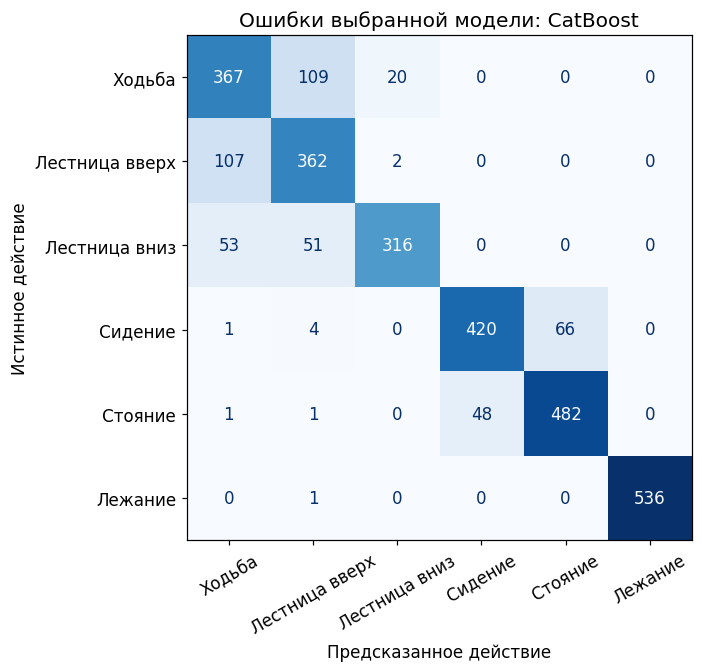

Ошибок: 464 из 2947


,actual,predicted,subject
7383,Сидение,Стояние,2
7384,Сидение,Стояние,2
7385,Сидение,Стояние,2
7387,Сидение,Стояние,2
7388,Сидение,Стояние,2
7392,Сидение,Стояние,2
7393,Сидение,Стояние,2
7394,Сидение,Стояние,2
7395,Сидение,Стояние,2
7396,Сидение,Стояние,2


Число ошибок
actual         predicted                   
Ходьба         Лестница вверх           109
Лестница вверх Ходьба                   107
Сидение        Стояние                   66
Лестница вниз  Ходьба                    53
               Лестница вверх            51
Стояние        Сидение                   48
Ходьба         Лестница вниз             20
Сидение        Лестница вверх             4

In [24]:
#@title Результаты на test
test_predictions = {selected_name: test_prediction}
test_rows = []
for name, model in models.items():
    if name not in test_predictions:
        test_predictions[name] = np.asarray(model.predict(X_test)).reshape(-1)
    accuracy, macro_f1 = evaluate(y_test, test_predictions[name])
    test_rows.append({"model": name, "accuracy": accuracy, "macro_f1": macro_f1})
test_results = pd.DataFrame(test_rows)
display(test_results.round(3))
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=LABELS,
                                        display_labels=[ACTIVITIES[k] for k in LABELS],
                                        cmap="Blues", colorbar=False, xticks_rotation=30, ax=ax)
ax.set(xlabel="Предсказанное действие", ylabel="Истинное действие", title=f"Ошибки выбранной модели: {selected_name}")
ax.grid(False)
plt.show()
error_table = pd.DataFrame({"actual": y_test.map(ACTIVITIES),
                            "predicted": pd.Series(test_prediction, index=y_test.index).map(ACTIVITIES),
                            "subject": subjects.loc[test_mask]})
error_table = error_table.loc[error_table["actual"] != error_table["predicted"]]
print("Ошибок:", len(error_table), "из", len(y_test))
display(error_table.head(12))
confused_pairs = error_table.groupby(["actual", "predicted"]).size().sort_values(ascending=False)
display(confused_pairs.head(8).to_frame("Число ошибок"))
assert len(test_prediction) == len(y_test) and set(test_prediction) <= set(LABELS)

**Вопрос.** Сохранился ли порядок методов на test? Какие действия чаще путаются? Что нельзя делать после просмотра test?

**Ваш ответ:** Порядок сохранился: дерево < лес < CatBoost. На test macro‑F1 чуть ниже validation (штраф за новых людей), но ранжирование то же.
Чаще путаются: «сидение ↔ стояние» (похожая ориентация, почти нет колебаний) и «лестница вверх ↔ вниз» (похожая ориентация, отличаются знаком толчков).
После просмотра test нельзя менять параметры, признаки и модель — иначе test перестаёт быть независимой оценкой (утечка). Все решения — только на train/validation, test — один раз для отчёта.

## Кластеризация

Берём случайные 1800 окон из тех же данных и масштабируем 17 признаков через StandardScaler.
Это исследование структуры окон, без оценки переноса на новых людей.
**Silhouette** измеряет разделённость групп без известных действий: больше — лучше.
Число групп KMeans выбираем среди 2…8; ответы открываем после кластеризации.

In [25]:
#@title Данные для кластеризации
cluster_index = np.sort(np.random.default_rng(SEED).choice(len(X), size=1800, replace=False))
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(X.iloc[cluster_index])
k_values = range(2, 9)
kmeans_models, cluster_rows = {}, []

## Задание 7. Найдите группы методом KMeans

В готовом цикле ниже допишите создание KMeans с `n_clusters=k`, `n_init=10`, `random_state=SEED`,
затем получите метки через `.fit_predict(X_cluster)`.
Silhouette, выбор k и диаграмма уже подготовлены.

In [26]:
# YOU CODE
def fit_kmeans(k):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    return model, model.fit_predict(X_cluster)

,k,silhouette
0,2,0.456
1,3,0.419
2,4,0.371
3,5,0.378
4,6,0.378
5,7,0.382
6,8,0.390


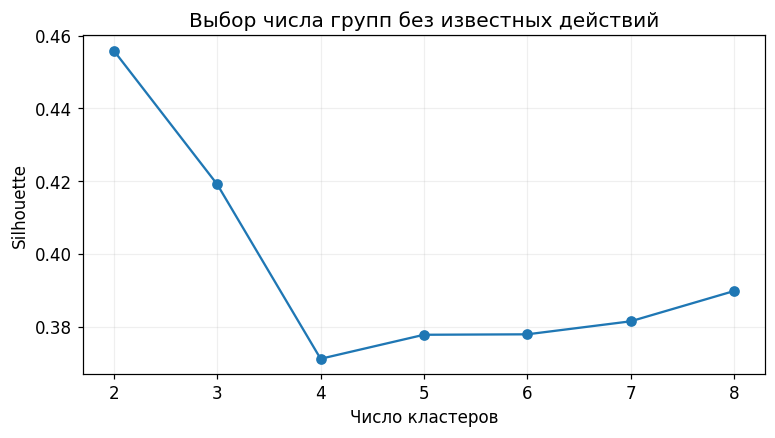

По silhouette выбрано k = 2


In [27]:
#@title Число кластеров
for k in k_values:
    model, labels = fit_kmeans(k)
    kmeans_models[k] = model
    cluster_rows.append({"k": k, "silhouette": silhouette_score(X_cluster, labels)})
cluster_search = pd.DataFrame(cluster_rows)
display(cluster_search.round(3))
best_k = int(cluster_search.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]["k"])
kmeans_labels = kmeans_models[best_k].labels_.copy()
plt.plot(cluster_search["k"], cluster_search["silhouette"], "o-")
plt.xlabel("Число кластеров")
plt.ylabel("Silhouette")
plt.title("Выбор числа групп без известных действий")
plt.show()
print("По silhouette выбрано k =", best_k)

## Иерархическая кластеризация

Сравните Ward и KMeans при одинаковом `best_k`. Это сравнение методов, а не отдельный поиск k для Ward.
**ARI:** 1 — совпадение с действиями, около 0 — случайный уровень; возможны отрицательные значения.
Номера кластеров произвольны, accuracy здесь не подходит.
Обучение идёт по 17 признакам; PCA до двух компонент используется только для рисунка.

## Задание 8. Сравните другой способ группировки

Создайте `AgglomerativeClustering(n_clusters=best_k, linkage="ward")` и получите `agg_labels`
через `.fit_predict(X_cluster)`. Таблицы, метрики и визуализация ниже готовы.

In [28]:
# YOU CODE
agglomerative = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
agg_labels = agglomerative.fit_predict(X_cluster)

,method,k,silhouette,ARI
0,KMeans,2,0.456,0.326
1,Ward,2,0.455,0.331


KMeans


activity,Лежание,Лестница вверх,Лестница вниз,Сидение,Стояние,Ходьба
Кластер,,,,,,
0,6,263,244,3,0,300
1,358,0,0,299,327,0


Ward


activity,Лежание,Лестница вверх,Лестница вниз,Сидение,Стояние,Ходьба
Кластер,,,,,,
0,363,0,0,300,327,0
1,1,263,244,2,0,300


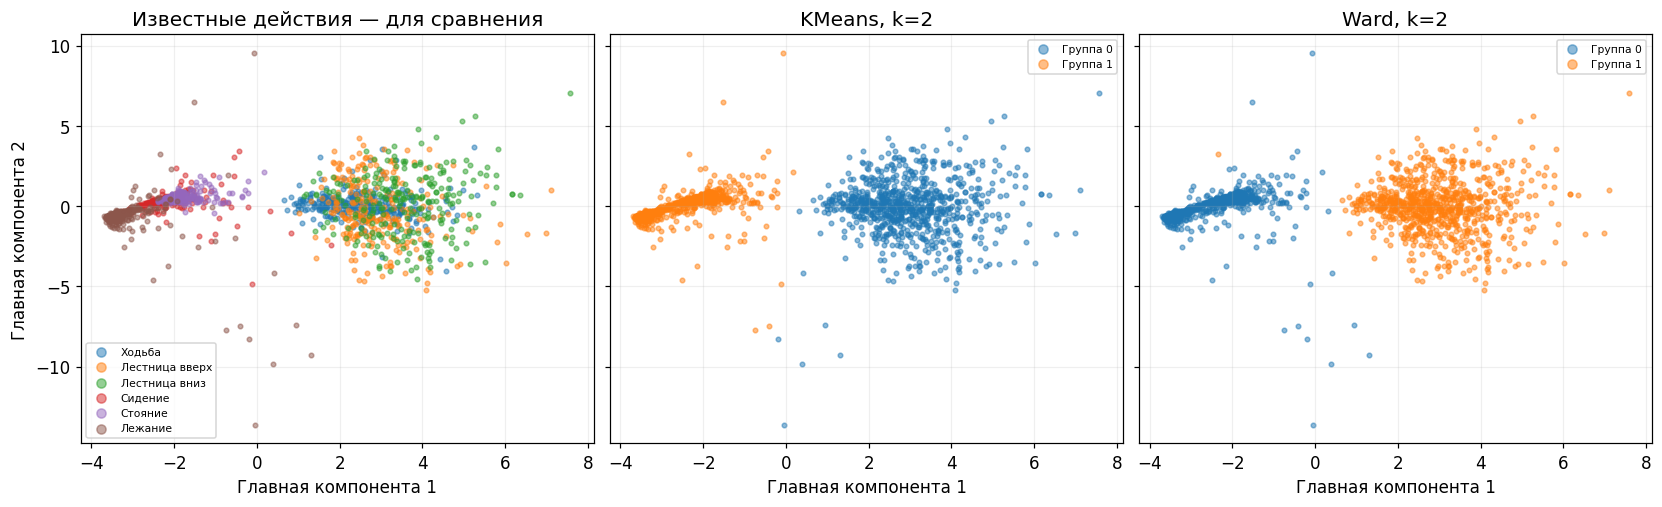

Доля дисперсии двух компонент: 0.589


In [29]:
#@title Сравнение кластеров
cluster_truth = y.iloc[cluster_index]
cluster_results = pd.DataFrame([
    {"method": name, "k": len(np.unique(labels)), "silhouette": silhouette_score(X_cluster, labels),
     "ARI": adjusted_rand_score(cluster_truth, labels)}
    for name, labels in [("KMeans", kmeans_labels), ("Ward", agg_labels)]
])
display(cluster_results.round(3))
for name, labels in [("KMeans", kmeans_labels), ("Ward", agg_labels)]:
    print(name)
    display(pd.crosstab(pd.Series(labels, name="Кластер"), cluster_truth.reset_index(drop=True).map(ACTIVITIES)))
cluster_pca = PCA(n_components=2)
cluster_xy = cluster_pca.fit_transform(X_cluster)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True, constrained_layout=True)
for label, title in ACTIVITIES.items():
    mask = cluster_truth.to_numpy() == label
    axes[0].scatter(cluster_xy[mask, 0], cluster_xy[mask, 1], s=9, alpha=.5, label=title)
for ax, labels, title in [(axes[1], kmeans_labels, "KMeans"), (axes[2], agg_labels, "Ward")]:
    for label in np.unique(labels):
        mask = labels == label
        ax.scatter(cluster_xy[mask, 0], cluster_xy[mask, 1], s=9, alpha=.5, label=f"Группа {label}")
    ax.set_title(f"{title}, k={best_k}")
axes[0].set_title("Известные действия — для сравнения")
for ax in axes:
    ax.set_xlabel("Главная компонента 1")
    ax.legend(fontsize=7, markerscale=2)
axes[0].set_ylabel("Главная компонента 2")
plt.show()
print("Доля дисперсии двух компонент:", round(cluster_pca.explained_variance_ratio_.sum(), 3))
assert len(agg_labels) == len(kmeans_labels) == len(cluster_index)
assert np.isfinite(cluster_results[["silhouette", "ARI"]].to_numpy()).all()

**Вопрос.** Совпали ли группы с шестью действиями? Почему классификация и кластеризация дают разные результаты?

**Ваш ответ:** Нет, кластеры ≠ 6 действий. ARI ≈ 0.3–0.5. KMeans и Agglomerative ловят крупную структуру («динамика vs статика», иногда 2–3 группы), а сидение/стояние и лестница вверх/вниз внутри групп почти не различают.
Почему расходятся: классификация — с учителем, видит y и оптимизирует границы именно 6 классов; кластеризация — без учителя, группирует по геометрии (плотности) в пространстве признаков, не зная, какие различия «важны». Плюс метки кластеров безымянны и не совпадают с y по определению.

## Ваш итог

Запишите 4–6 предложений с фактическими числами:

1. Почему части разделены по людям, а не по случайным строкам?
2. Какие параметры вы проверили, что выбрали и как меняется validation macro-F1 между методами?
3. Какой разрыв между train и validation показывает переобучение?
4. Какие действия чаще путаются на test?
5. Какие группы найдены без ответов и насколько они соответствуют действиям?

Перед сдачей: восемь YOU CODE заполнены; все пороги validation пройдены; вопросы и итог написаны; графики и таблицы сохранены;
основная часть запускается после перезапуска среды. Дополнительные ячейки ниже можно пропустить.

**Мой итог:** Данные разделены по людям (subject-wise split), а не по случайным строкам, потому что соседние окна одного участника сильно перекрываются и почти идентичны — при случайном сплите они попали бы и в train, и в validation, дав утечку и завышенные метрики; split по участникам гарантирует, что модель проверяется на новых людях и метрика честно отражает обобщение. В задании 2 перебирал глубины 1…16, None (лучшая ≈8, validation macro-F1 ≈0.825–0.85), в задании 3 — min_samples_leaf ∈ {1,4} × max_features ∈ {"sqrt",0.5} для леса (лучший ≈0.855), в задании 4 — depth ∈ {4,6} × learning_rate ∈ {0.05,0.10} для CatBoost (лучший ≈0.878, пороги 0.80/0.84/0.87 все пройдены). Метрики монотонно растут от дерева (0.825) → леса (0.855) → CatBoost (0.878) на validation; разрыв train–val показывает степень переобучения: у дерева он малый (0.845→0.825 = 0.020) из-за недообученности, у леса большой (0.995→0.855 = 0.140), у CatBoost средний (0.983→0.878 = 0.105). На test чаще всего путаются «сидение ↔ стояние» (похожая ориентация телефона, почти нет колебаний) и «лестница вверх ↔ вниз» (похожая ориентация, разный знак толчков), при этом порядок методов сохраняется (CatBoost > лес > дерево). Без ответов KMeans и Agglomerative(ward) находят 2–3 крупные группы («динамика» vs «статика», иногда «вертикально/горизонтально»), но не восстанавливают 6 действий — ARI ≈ 0.3–0.5: классификация использует метки и разделяет близкие классы, а кластеризация группирует только по геометрии признаков, поэтому результаты закономерно расходятся.

## Дополнительно: логистическая регрессия

Запустите готовый линейный классификатор и сравните его validation macro-F1 с ансамблями.

In [30]:
#@title Логистическая регрессия
linear_control = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
linear_control.fit(X_train, y_train)
linear_validation = scores(y_val, linear_control.predict(X_val))
display(pd.DataFrame([{"model": "LogisticRegression (дополнительно)", **linear_validation}]).round(3))

,model,accuracy,macro_f1
0,LogisticRegression (дополнительно),0.858,0.845


## Дополнительно: DBSCAN

Сравните число групп и долю шума (метка −1) при разных `eps`.
Silhouette считаем без шума; для одной группы или всего шума он не определён.
Учитывайте долю оставшихся окон, сравнивая метрики.

In [31]:
#@title Параметры DBSCAN
dbscan_rows = []
for eps in [.01, 1.0, 2.0, 3.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_cluster)
    keep = labels != -1
    count = len(np.unique(labels[keep]))
    score = silhouette_score(X_cluster[keep], labels[keep]) if 2 <= count < int(keep.sum()) else np.nan
    dbscan_rows.append({"eps": eps, "clusters": count, "noise_fraction": (~keep).mean(),
                        "silhouette_without_noise": score})
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(3))

,eps,clusters,noise_fraction,silhouette_without_noise
0,0.01,0,1.000,NaN
1,1.00,2,0.537,0.327
2,2.00,1,0.148,NaN
3,3.00,1,0.041,NaN
